<a href="https://colab.research.google.com/github/FOFM030711/SIMULACION-II/blob/main/Ejercicio2_%20Integral_estoc%C3%A1stica.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>


# <span style="color:brown;">**Ejercicio 2: Comprobación por simulación para $t=1$**</span>

**Alumno:** Florencio Florencio Miriam Lizeth

<span style="color:purple;">**Objetivo:**</span>
Comprobar numéricamente, mediante el método de simulación Monte Carlo, los resultados teóricos obtenidos en el Ejercicio 1 para la integral del cuadrado del movimiento browniano estándar, definida como

$$I=\int_0^1 W_s^2\,ds .$$

Resultados teóricos (para $t=1$):

$$\mathbb{E}\left[\int_0^1 W_s^2\,ds\right]=\frac{1^2}{2}=0.5,\qquad
\mathrm{Var}\left[\int_0^1 W_s^2\,ds\right]=\frac{1^4}{3}\approx 0.3333 .$$

---

**I. Fundamento teórico**

**Media.** Por Fubini y $\mathbb{E}[W_s^2]=s$:
$$\mathbb{E}[I]=\int_0^1 \mathbb{E}[W_s^2]\,ds=\int_0^1 s\,ds=\frac12 .$$

**Segundo momento.** Con el teorema de Isserlis (Wick) para variables gaussianas centradas,
$\mathbb{E}[W_s^2W_u^2]=su+2\min(s,u)^2$, por lo que
$$\mathbb{E}[I^2]=\int_0^1\!\!\int_0^1 \big(su+2\min(s,u)^2\big)\,ds\,du=\frac14+2\cdot\frac16=\frac7{12}.$$

**Varianza.**
$$\mathrm{Var}[I]=\mathbb{E}[I^2]-\mathbb{E}[I]^2=\frac7{12}-\frac14=\frac13 .$$

## II. Algoritmo de simulación

1. **Discretización:** dividir $[0,1]$ en $N$ pasos, $\Delta t=1/N$, $t_i=i\Delta t$.
2. **Camino browniano:** $Z_i\sim N(0,1)$ i.i.d., $W_{t_i}=W_{t_{i-1}}+\sqrt{\Delta t}\,Z_i$, con $W_0=0$.
3. **Integral (suma de Riemann):** $I=\sum_{i=1}^N W_{t_i}^2\,\Delta t$.
4. **Repetir** los pasos 2–3 $M$ veces para obtener $I_1,\dots,I_M$.
5. **Estimar:** $\bar I=\frac1M\sum_j I_j$ y $S^2=\frac1{M-1}\sum_j (I_j-\bar I)^2$.

## III. Librerías y parámetros

In [1]:
# Importación de bibliotecas necesarias para la simulación Monte Carlo

import numpy as np                  # Permite realizar cálculos numéricos y generar variables aleatorias.
import matplotlib.pyplot as plt     # Se utiliza para crear gráficas y visualizar los resultados.
from scipy import stats              # Proporciona herramientas estadísticas para el análisis de datos.
import pandas as pd                 # Permite organizar los resultados en tablas y DataFrames.

In [2]:

# Semilla para reproducibilidad
rng = np.random.default_rng(seed=2026)

# ---- Parámetros de la simulación ----
T = 1.0        # horizonte de tiempo t = 1
N = 1000       # número de pasos de discretización
M = 10_000     # número de trayectorias (réplicas Monte Carlo)
dt = T / N     # paso de tiempo

# ---- Valores teóricos (Ejercicio 1) ----
media_teorica = T**2 / 2
var_teorica   = T**4 / 3

print(f"dt = {dt}")
print(f"E[I]   teórica = {media_teorica}")
print(f"Var[I] teórica = {var_teorica:.6f}")

dt = 0.001
E[I]   teórica = 0.5
Var[I] teórica = 0.333333


## IV. Simulación de una sola trayectoria (ilustración)

Antes de vectorizar, construimos **una** trayectoria paso a paso para ver qué calcula el algoritmo.
El área bajo la curva $W_s^2$ (aproximada por la suma de Riemann) es el valor de $I$ para esa trayectoria.

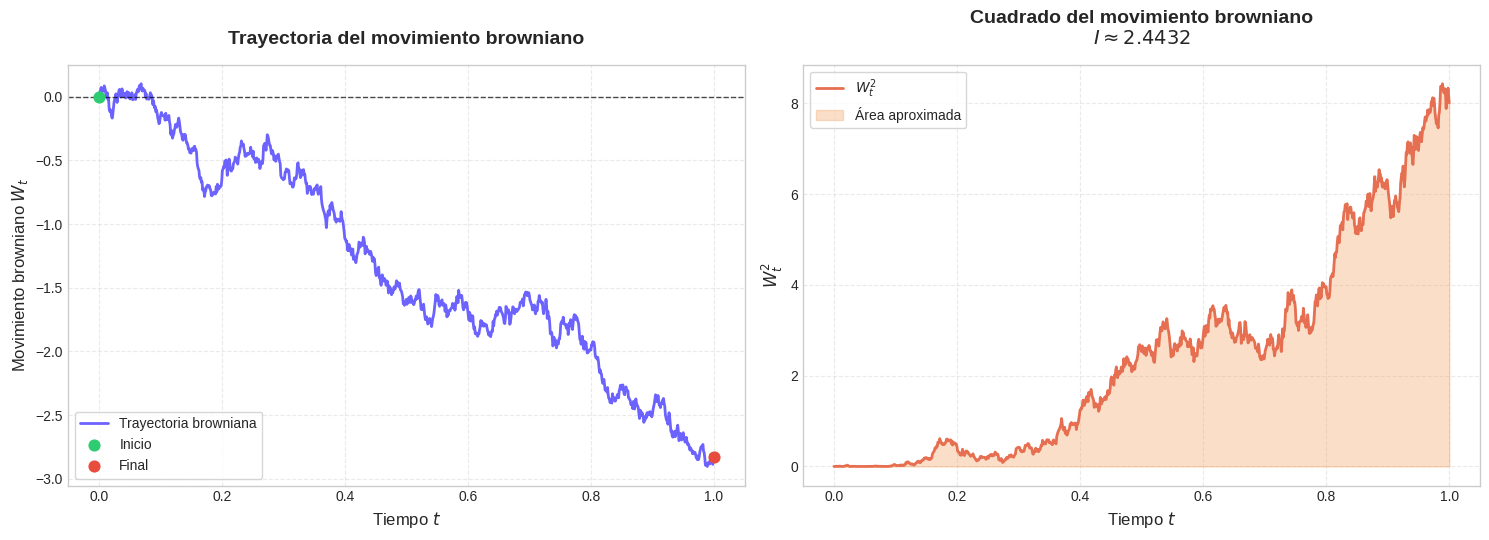

Valor aproximado de la integral: I = 2.443212


In [4]:
# Generación de los puntos del intervalo de tiempo
t = np.linspace(0, T, N + 1)

# Generación de variables aleatorias normales estándar independientes
Z = rng.standard_normal(N)

# Construcción de la trayectoria browniana
# W_0 = 0 y W_ti = W_t(i-1) + sqrt(dt) * Z_i
W = np.concatenate(([0.0], np.cumsum(np.sqrt(dt) * Z)))

# Aproximación numérica de la integral del cuadrado del movimiento browniano
I_una = np.sum(W[1:]**2) * dt


# Configuración general de las gráficas
plt.style.use("seaborn-v0_8-whitegrid")

fig, ax = plt.subplots(1, 2, figsize=(15, 5.5))

# GRÁFICA 1: TRAYECTORIA DEL MOVIMIENTO BROWNIANO

ax[0].plot(
    t, W,
    color="#6C63FF",
    linewidth=2,
    label="Trayectoria browniana"
)

# Línea horizontal en cero
ax[0].axhline(
    y=0,
    color="black",
    linewidth=1,
    linestyle="--",
    alpha=0.7
)

# Punto inicial
ax[0].scatter(
    t[0], W[0],
    color="#2ECC71",
    s=60,
    zorder=5,
    label="Inicio"
)

# Punto final
ax[0].scatter(
    t[-1], W[-1],
    color="#E74C3C",
    s=60,
    zorder=5,
    label="Final"
)

ax[0].set_title(
    "Trayectoria del movimiento browniano",
    fontsize=14,
    fontweight="bold",
    pad=15
)

ax[0].set_xlabel("Tiempo $t$", fontsize=12)
ax[0].set_ylabel("Movimiento browniano $W_t$", fontsize=12)

ax[0].legend(frameon=True, fontsize=10)
ax[0].grid(True, linestyle="--", alpha=0.4)

# GRÁFICA 2: CUADRADO DEL MOVIMIENTO BROWNIANO
ax[1].plot(
    t, W**2,
    color="#E76F51",
    linewidth=2,
    label="$W_t^2$"
)

# Área bajo la curva, que representa la integral
ax[1].fill_between(
    t, 0, W**2,
    color="#F4A261",
    alpha=0.35,
    label="Área aproximada"
)

ax[1].set_title(
    f"Cuadrado del movimiento browniano\n"
    f"$I \\approx {I_una:.4f}$",
    fontsize=14,
    fontweight="bold",
    pad=15
)

ax[1].set_xlabel("Tiempo $t$", fontsize=12)
ax[1].set_ylabel("$W_t^2$", fontsize=12)

ax[1].legend(frameon=True, fontsize=10)
ax[1].grid(True, linestyle="--", alpha=0.4)

# Ajustar espacios entre las gráficas
plt.tight_layout()

# Mostrar las gráficas
plt.show()


# Mostrar el valor numérico de la integral
print(f"Valor aproximado de la integral: I = {I_una:.6f}")

## V Simulación Monte Carlo vectorizada

Generar una matriz de $M\times N$ normales ocupa $\approx 80$ MB para $M=10^4$, $N=10^3$.
Para que el código sea escalable se procesa **por lotes** (*batches*), de modo que se pueda subir $M$ sin agotar memoria.

In [7]:

# FUNCIÓN PARA SIMULAR LA INTEGRAL DEL CUADRADO DEL MOVIMIENTO
# BROWNIANO MEDIANTE EL MÉTODO MONTE CARLO


def simular_integral(M, N, T=1.0, batch=2000, rng=rng):

    # 1. DISCRETIZACIÓN DEL INTERVALO DE TIEMPO

    # Se calcula el tamaño de cada subintervalo de tiempo
    # mediante dt = T/N.
    dt = T / N
    I = np.empty(M)
    hecho = 0

    # 2. GENERACIÓN DE TRAYECTORIAS BROWNIANAS

    # El ciclo continúa hasta completar las M simulaciones.

    while hecho < M:

        # Se determina el número de trayectorias que se generarán
        # en el bloque actual. Se evita exceder M.
        m = min(batch, M - hecho)
        Z = rng.standard_normal((m, N))

        # 3. CONSTRUCCIÓN DEL MOVIMIENTO BROWNIANO

        W = np.cumsum(np.sqrt(dt) * Z, axis=1)

        # 4. APROXIMACIÓN DE LA INTEGRAL

        I[hecho:hecho + m] = np.sum(W**2, axis=1) * dt

        hecho += m

    return I


# Se ejecuta la función utilizando los valores previamente defnidos

I = simular_integral(M, N, T)

print("Primeros 5 valores de I:", np.round(I[:5], 4))

Primeros 5 valores de I: [1.1634 1.8108 0.1578 0.2151 0.1018]


## VI. Estimadores: media y varianza muestral

$$\bar I=\frac1M\sum_{j=1}^M I_j,\qquad S^2=\frac1{M-1}\sum_{j=1}^M (I_j-\bar I)^2 .$$

In [8]:
I_barra = I.mean()
S2      = I.var(ddof=1)          # ddof=1  ->  divide entre (M-1)

# Errores estándar de los estimadores
ee_media = np.sqrt(S2 / M)
# Var(S^2) ≈ (mu4 - sigma^4 (M-3)/(M-1)) / M ; usamos el momento central 4 muestral
mu4 = np.mean((I - I_barra)**4)
ee_var = np.sqrt((mu4 - S2**2) / M)

tabla = pd.DataFrame({
    "Teórico":   [media_teorica, var_teorica],
    "Simulado":  [I_barra, S2],
    "Error abs.": [abs(I_barra - media_teorica), abs(S2 - var_teorica)],
    "Error est. (MC)": [ee_media, ee_var],
}, index=["Media  E[I]", "Varianza Var[I]"])
tabla.round(5)

,Teórico,Simulado,Error abs.,Error est. (MC)
Media E[I],0.50000,0.50370,0.00370,0.00578
Varianza Var[I],0.33333,0.33415,0.00082,0.01196


## Intervalos de confianza del 95 %

Con el propósito de evaluar la precisión de las estimaciones obtenidas mediante la simulación Monte Carlo, se construyen intervalos de confianza al 95% para la esperanza matemática y la varianza de la integral.

### 1. Intervalo de confianza para la media

Se utiliza el intervalo de confianza basado en la distribución *t* de Student, considerando $M-1$ grados de libertad:

$$
IC_{95\%}(\mathbb{E}[I])
=
\overline{I}
\pm
t_{M-1,0.975}\frac{S}{\sqrt{M}}.
$$

Donde $\overline{I}$ representa la media muestral, $S$ la desviación estándar muestral y $M$ el número de simulaciones realizadas.

### 2. Intervalo de confianza para la varianza

Para estimar el intervalo de confianza de la varianza, se emplea una aproximación asintótica basada en el cuarto momento central de la muestra:

$$
IC_{95\%}(\operatorname{Var}(I))
=
S^2\pm1.96\,\widehat{EE}(S^2),
$$

donde el error estándar estimado de la varianza se calcula como:

$$
\widehat{EE}(S^2)
=
\sqrt{\frac{\hat{\mu}_4-S^4}{M}}.
$$

En esta expresión, $\hat{\mu}_4$ corresponde al cuarto momento central muestral y $S^2$ a la varianza muestral.

Se opta por esta aproximación en lugar del intervalo clásico basado en la distribución $\chi^2$, debido a que dicho intervalo supone que las observaciones provienen de una distribución normal. Sin embargo, la integral del cuadrado del movimiento browniano presenta una distribución asimétrica y con colas pesadas, por lo que el uso del intervalo clásico podría proporcionar estimaciones poco adecuadas de la incertidumbre.

### Interpretación

Los intervalos de confianza permiten evaluar si las estimaciones obtenidas mediante simulación son compatibles con los resultados teóricos. Si los valores teóricos de la esperanza matemática y la varianza se encuentran dentro de sus respectivos intervalos de confianza, se considera que los resultados numéricos son consistentes con los valores analíticos obtenidos previamente.

In [9]:
alpha = 0.05
# IC para la media
tcrit = stats.t.ppf(1 - alpha/2, df=M-1)
ic_media = (I_barra - tcrit*ee_media, I_barra + tcrit*ee_media)

# IC para la varianza (asintótico, usa el cuarto momento: válido sin suponer normalidad)
z = stats.norm.ppf(1 - alpha/2)
ic_var = (S2 - z*ee_var, S2 + z*ee_var)

print(f"IC 95% media    : ({ic_media[0]:.4f}, {ic_media[1]:.4f})  | teórica = {media_teorica}  "
      f"-> {'DENTRO' if ic_media[0] <= media_teorica <= ic_media[1] else 'FUERA'}")
print(f"IC 95% varianza : ({ic_var[0]:.4f}, {ic_var[1]:.4f})  | teórica = {var_teorica:.4f}  "
      f"-> {'DENTRO' if ic_var[0] <= var_teorica <= ic_var[1] else 'FUERA'}")

IC 95% media    : (0.4924, 0.5150)  | teórica = 0.5  -> DENTRO
IC 95% varianza : (0.3107, 0.3576)  | teórica = 0.3333  -> DENTRO


## VII. Distribución de las realizaciones de $I$


**HISTOGRAMA DE LA INTEGRAL DEL CUADRADO DEL MOVIMIENTO BROWNIANO**

 Se representa la distribución de los valores obtenidos
 mediante la simulación Monte Carlo.


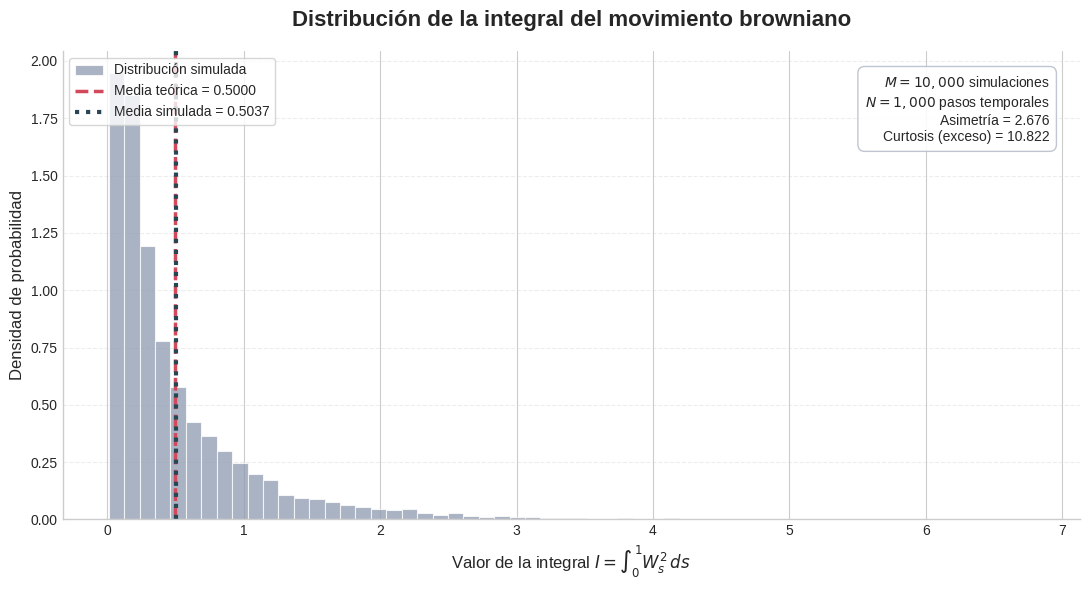

Asimetría de la distribución: 2.6756
Curtosis en exceso: 10.8215


In [10]:
# Se crea la figura y el eje donde se representará el histograma
fig, ax = plt.subplots(figsize=(11, 6))


# bins=60 establece el número de intervalos del histograma.
ax.hist(
    I,
    bins=60,
    density=True,
    color="#8E9AAF",
    alpha=0.75,
    edgecolor="white",
    linewidth=0.8,
    label="Distribución simulada"
)


# Se agrega una línea vertical discontinua para señalar
# la esperanza matemática teórica de la integral.
ax.axvline(
    media_teorica,
    color="#D1495B",
    linestyle="--",
    linewidth=2.5,
    label=f"Media teórica = {media_teorica:.4f}"
)


# Se agrega una línea vertical punteada que representa
# la media calculada a partir de las simulaciones.
ax.axvline(
    I_barra,
    color="#264653",
    linestyle=":",
    linewidth=3,
    label=f"Media simulada = {I_barra:.4f}"
)


# Título principal de la gráfica
ax.set_title(
    "Distribución de la integral del movimiento browniano",
    fontsize=16,
    fontweight="bold",
    pad=18
)

# Etiquetas de los ejes
ax.set_xlabel(
    r"Valor de la integral $I=\int_0^1 W_s^2\,ds$",
    fontsize=12
)

ax.set_ylabel(
    "Densidad de probabilidad",
    fontsize=12
)


# Se agrega un recuadro con el número de simulaciones,
# la asimetría y la curtosis de la distribución.
texto_estadisticas = (
    f"$M = {M:,}$ simulaciones\n"
    f"$N = {N:,}$ pasos temporales\n"
    f"Asimetría = {stats.skew(I):.3f}\n"
    f"Curtosis (exceso) = {stats.kurtosis(I):.3f}"
)

ax.text(
    0.97, 0.95,
    texto_estadisticas,
    transform=ax.transAxes,
    fontsize=10,
    verticalalignment="top",
    horizontalalignment="right",
    bbox=dict(
        boxstyle="round,pad=0.5",
        facecolor="white",
        edgecolor="#B8C0CC",
        alpha=0.9
    )
)

# Se configura una cuadrícula tenue para facilitar
# la lectura de los valores del histograma.
ax.grid(
    axis="y",
    linestyle="--",
    alpha=0.35
)

# Se eliminan los bordes superior y derecho para
# obtener una apariencia más limpia.
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

# Se ajusta la leyenda para identificar las líneas
# de referencia y la distribución simulada.
ax.legend(
    loc="upper left",
    frameon=True,
    fontsize=10
)

# Se ajustan los espacios de la figura
plt.tight_layout()

# Se muestra la gráfica
plt.show()

# Se calcula e imprime la asimetría de la distribución.
# Un valor positivo indica que la distribución presenta
# una cola más larga hacia la derecha.
print(f"Asimetría de la distribución: {stats.skew(I):.4f}")

# Se calcula e imprime la curtosis en exceso.
# Un valor positivo indica mayor presencia de valores extremos
# respecto a una distribución normal.
print(f"Curtosis en exceso: {stats.kurtosis(I):.4f}")

**Observación:** La distribución obtenida presenta una clara asimetría hacia la derecha y no sigue una distribución normal. Esto es esperado, ya que la integral siempre toma valores positivos y depende del cuadrado del movimiento browniano. Sin embargo, a pesar de esta forma de distribución, los valores de la media y la varianza estimados mediante la simulación se aproximan bastante a los resultados teóricos, lo que permite comprobar que el método Monte Carlo proporciona resultados consistentes.

## VIII. Convergencia de los estimadores al aumentar $M$

Por la Ley de los Grandes Números, $\bar I_M\to \mathbb{E}[I]$ y $S_M^2\to \mathrm{Var}[I]$. Se grafican los estimadores acumulados (con los primeros $k$ valores) y la banda de $\pm 2$ errores estándar para la media.

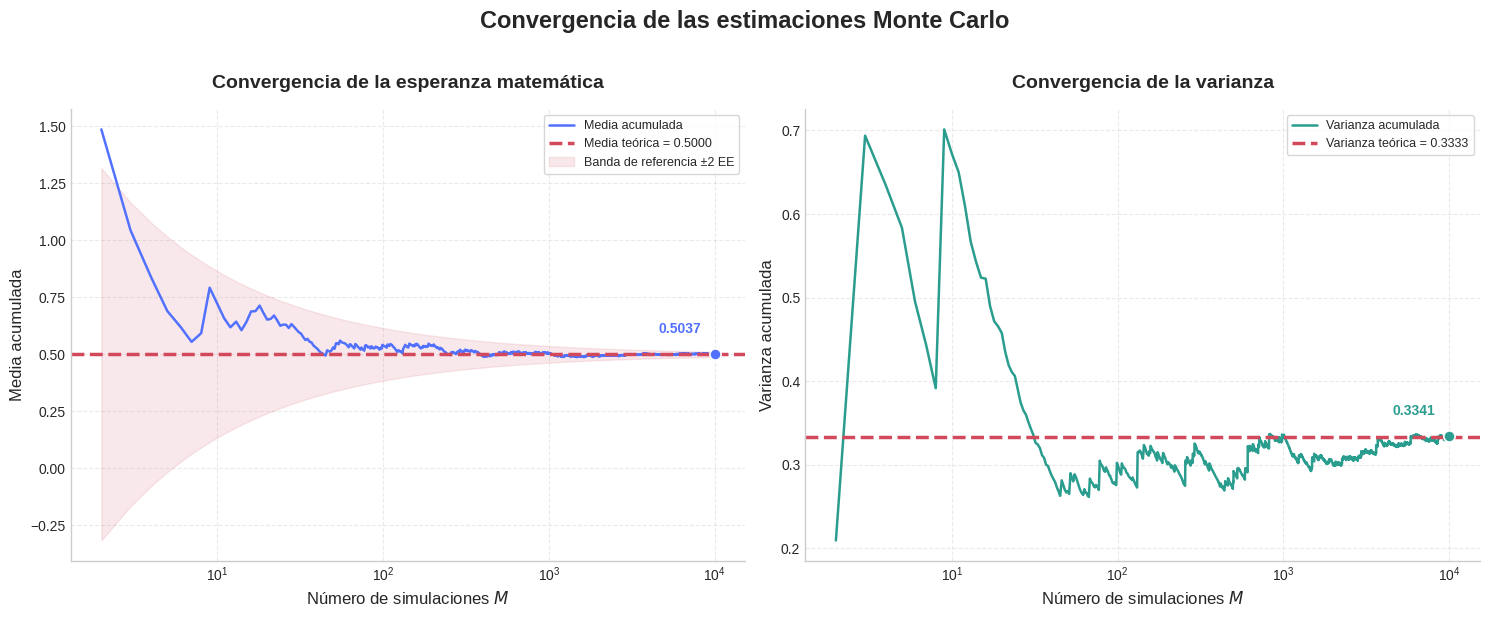

In [12]:

# CONVERGENCIA DE LA MEDIA Y LA VARIANZA

k = np.arange(2, M + 1)

# CÁLCULO DE LA MEDIA ACUMULADA

cum_media = np.cumsum(I)[1:] / k

#  CÁLCULO DE LA VARIANZA ACUMULADA

cum_var = (
    np.cumsum(I**2)[1:] - k * cum_media**2
) / (k - 1)


# Se establece un estilo visual limpio para las gráficas.
plt.style.use("seaborn-v0_8-whitegrid")

# Se crean dos gráficas lado a lado.
fig, ax = plt.subplots(1, 2, figsize=(15, 6))


# Se representa la media acumulada conforme aumenta
# el número de simulaciones.
ax[0].plot(
    k,
    cum_media,
    color="#5271FF",
    linewidth=1.8,
    label="Media acumulada"
)

# Se agrega una línea horizontal que representa
# el valor teórico de la esperanza matemática.
ax[0].axhline(
    media_teorica,
    color="#D1495B",
    linestyle="--",
    linewidth=2.5,
    label=f"Media teórica = {media_teorica:.4f}"
)

# Se calcula el error estándar teórico de la media
# para cada número de simulaciones.
EE_media = np.sqrt(var_teorica / k)

# Se agrega una banda de referencia de aproximadamente
# dos errores estándar alrededor de la media teórica.
ax[0].fill_between(
    k,
    media_teorica - 2 * EE_media,
    media_teorica + 2 * EE_media,
    color="#D1495B",
    alpha=0.12,
    label="Banda de referencia ±2 EE"
)

# Se marca el último valor de la media acumulada.
ax[0].scatter(
    k[-1],
    cum_media[-1],
    color="#5271FF",
    s=65,
    edgecolor="white",
    linewidth=1.2,
    zorder=5
)

# Se agrega una anotación con el valor final estimado.
ax[0].annotate(
    f"{cum_media[-1]:.4f}",
    xy=(k[-1], cum_media[-1]),
    xytext=(-10, 15),
    textcoords="offset points",
    ha="right",
    fontsize=10,
    fontweight="bold",
    color="#5271FF"
)

# Se configura el título y las etiquetas de los ejes.
ax[0].set_title(
    "Convergencia de la esperanza matemática",
    fontsize=14,
    fontweight="bold",
    pad=15
)

ax[0].set_xlabel("Número de simulaciones $M$", fontsize=12)
ax[0].set_ylabel("Media acumulada", fontsize=12)

# Se utiliza escala logarítmica para observar mejor
# la convergencia desde pocas hasta muchas simulaciones.
ax[0].set_xscale("log")

# Se configura la leyenda y la cuadrícula.
ax[0].legend(loc="best", fontsize=9, frameon=True)
ax[0].grid(True, linestyle="--", alpha=0.4)


# Se representa la varianza acumulada de las simulaciones.
ax[1].plot(
    k,
    cum_var,
    color="#2A9D8F",
    linewidth=1.8,
    label="Varianza acumulada"
)

# Se agrega una línea horizontal con el valor teórico
# de la varianza de la integral.
ax[1].axhline(
    var_teorica,
    color="#D1495B",
    linestyle="--",
    linewidth=2.5,
    label=f"Varianza teórica = {var_teorica:.4f}"
)

# Se marca el último valor de la varianza acumulada.
ax[1].scatter(
    k[-1],
    cum_var[-1],
    color="#2A9D8F",
    s=65,
    edgecolor="white",
    linewidth=1.2,
    zorder=5
)

# Se agrega una anotación con el valor final estimado.
ax[1].annotate(
    f"{cum_var[-1]:.4f}",
    xy=(k[-1], cum_var[-1]),
    xytext=(-10, 15),
    textcoords="offset points",
    ha="right",
    fontsize=10,
    fontweight="bold",
    color="#2A9D8F"
)

# Se configura el título y las etiquetas de los ejes.
ax[1].set_title(
    "Convergencia de la varianza",
    fontsize=14,
    fontweight="bold",
    pad=15
)

ax[1].set_xlabel("Número de simulaciones $M$", fontsize=12)
ax[1].set_ylabel("Varianza acumulada", fontsize=12)

# Se utiliza escala logarítmica en el eje horizontal.
ax[1].set_xscale("log")

# Se configura la leyenda y la cuadrícula.
ax[1].legend(loc="best", fontsize=9, frameon=True)
ax[1].grid(True, linestyle="--", alpha=0.4)

# Se eliminan los bordes superiores y derechos
# para obtener una apariencia más limpia.
for a in ax:
    a.spines["top"].set_visible(False)
    a.spines["right"].set_visible(False)

# Se agrega un título general a ambas gráficas.
fig.suptitle(
    "Convergencia de las estimaciones Monte Carlo",
    fontsize=17,
    fontweight="bold",
    y=1.02
)

# Se ajustan los espacios entre las gráficas.
plt.tight_layout()

# Se muestran las gráficas.
plt.show()

Convergencia de la media: se observa cómo la media acumulada se estabiliza alrededor del valor teórico de $0.5$. La banda sombreada representa una referencia de aproximadamente dos errores estándar, cuya amplitud disminuye conforme aumenta el número de simulaciones.


Convergencia de la varianza: muestra cómo la varianza muestral se aproxima al valor teórico de $1/3$, aunque puede presentar fluctuaciones más pronunciadas debido a la asimetría y las colas pesadas de la distribución.

## IX. Efecto de la discretización ($N$): sesgo de la suma de Riemann

Con la suma derecha, $t_i=i/N$ y $\mathbb{E}[W_{t_i}^2]=t_i$, así que el valor esperado **exacto del estimador discreto** es
$$\mathbb{E}[I_N]=\Delta t\sum_{i=1}^N t_i=\frac{N+1}{2N}=\frac12+\frac1{2N}.$$
Es decir, hay un pequeño **sesgo positivo** de orden $1/(2N)$ (para $N=1000$ vale $0.0005$, mucho menor que el error Monte Carlo $\approx 0.006$).
Se separan así los dos tipos de error: **sesgo por discretización** ($N$) y **error estadístico** ($M$).

In [14]:
from IPython.display import display, HTML

Ns = [5, 10, 50, 100, 500, 10000]
M_N = 20_000

filas = []

# Simulamos la integral para cada valor de N
for n in Ns:
    In = simular_integral(M_N, n, T, batch=5000)

    filas.append({
        "N": n,
        "Media teórica discreta": (n + 1) / (2 * n),
        "Media simulada": In.mean(),
        "Varianza simulada": In.var(ddof=1),
        "Error respecto a 0.5": In.mean() - media_teorica
    })

df_N = pd.DataFrame(filas).set_index("N")

# Estilo sencillo y limpio para la tabla
tabla = (
    df_N.style
    .format("{:.5f}")
    .set_table_styles([
        {
            "selector": "th",
            "props": [
                ("background-color", "#EAEAEA"),
                ("color", "#333333"),
                ("font-weight", "bold"),
                ("text-align", "center"),
                ("padding", "8px")
            ]
        },
        {
            "selector": "td",
            "props": [
                ("text-align", "center"),
                ("padding", "7px"),
                ("border-bottom", "1px solid #DDDDDD")
            ]
        },
        {
            "selector": "table",
            "props": [
                ("border-collapse", "collapse"),
                ("width", "100%"),
                ("font-family", "Arial"),
                ("font-size", "13px")
            ]
        }
    ])
    .set_properties(**{"background-color": "#FFFFFF"})
)

display(HTML(tabla.to_html()))

,Media teórica discreta,Media simulada,Varianza simulada,Error respecto a 0.5
N,,,,
5,0.60000,0.60157,0.48362,0.10157
10,0.55000,0.54893,0.42055,0.04893
50,0.51000,0.51031,0.34512,0.01031
100,0.50500,0.51282,0.35117,0.01282
500,0.50100,0.49252,0.32398,-0.00748
10000,0.50005,0.49922,0.33888,-0.00078


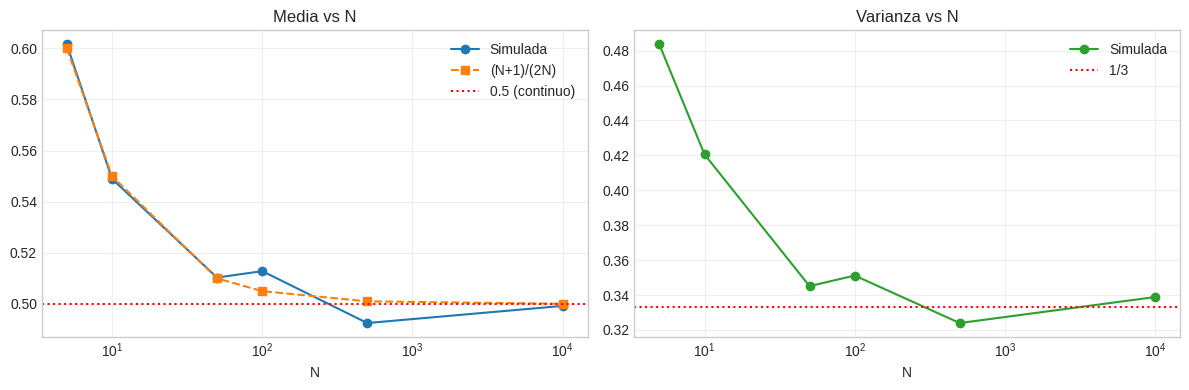

In [18]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(df_N.index, df_N["Media simulada"], "o-", label="Simulada")
ax[0].plot(df_N.index, df_N.iloc[:, 0], "s--", label="(N+1)/(2N)")
ax[0].axhline(0.5, color="red", ls=":", label="0.5 (continuo)")
ax[0].set_xscale("log"); ax[0].set_xlabel("N"); ax[0].set_title("Media vs N"); ax[0].legend(); ax[0].grid(alpha=.3)

ax[1].plot(df_N.index, df_N["Varianza simulada"], "o-", color="tab:green", label="Simulada")
ax[1].axhline(1/3, color="red", ls=":", label="1/3")
ax[1].set_xscale("log"); ax[1].set_xlabel("N"); ax[1].set_title("Varianza vs N"); ax[1].legend(); ax[1].grid(alpha=.3)
plt.tight_layout(); plt.show()

## X. Verificación con otro método (sin integral): chequeo del segundo momento

Como comprobación adicional, calculamos $\mathbb{E}[I^2]$ simulado y lo comparamos con $7/12\approx0.5833$.

In [28]:
E_I2_sim = np.mean(I**2)
print(f"E[I^2] simulado = {E_I2_sim:.5f}   |  teórico 7/12 = {7/12:.5f}")
print(f"Var[I] = E[I^2] - E[I]^2 = {E_I2_sim - I_barra**2:.5f}  |  teórica 1/3 = {1/3:.5f}")


E[I^2] simulado = 0.58783   |  teórico 7/12 = 0.58333
Var[I] = E[I^2] - E[I]^2 = 0.33412  |  teórica 1/3 = 0.33333


## <span style="color:orange">**XI Conclusión:**</span>
*   Los resultados de la simulación se acercan bastante a los valores teóricos de la media (0.5) y la varianza (0.3333), lo que indica que las simulaciones se realizaron correctamente.

*   Los valores teóricos se encuentran dentro de los intervalos de confianza del 95 %, por lo que podemos considerar que los resultados obtenidos son consistentes con lo esperado.

*   Al aumentar el número de simulaciones y los pasos de discretización, la aproximación mejora y los resultados tienden a estabilizarse.

En general, este ejercicio nos permitió comprobar mediante Monte Carlo los resultados teóricos de la integral del movimiento browniano y entender cómo influye el número de simulaciones en la precisión de los resultados.